# Low-fidelity prototype of the two dashboard screens

**Data source:** none (layout only); the dashboard will use `data/processed/hotel_bookings_clean.csv` and `country_names.csv`.
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Clean wireframes of the main screen and the detail screen (Part 4, task 4.3), drawn at the proportions of the minimum desktop size, 1280 × 800 px. Boxes show where each KPI, chart, control and text goes; the small drawings inside the chart boxes only show the chart type, not real data.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: layout grid](#4.-Analysis:-layout-grid)
5. [Accessible visualisation: wireframes](#5.-Accessible-visualisation:-wireframes)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

IMAGES_DIR = Path('../images')
OUTPUT_DIR = Path('lowfi_prototype_output')
IMAGES_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

SCREEN_W, SCREEN_H = 1280, 800          # minimum desktop size, in px
INK, GREY, PALE = '#1A1A1A', '#595959', '#F2F2F2'
plt.rcParams.update({'font.family': 'DejaVu Sans'})
print('Python', sys.version.split()[0], '| matplotlib', matplotlib.__version__)

Python 3.13.18 | matplotlib 3.11.2


## 1. Data loading

No data is loaded: a low-fidelity prototype shows structure, not values (course 03, prototype techniques).

## 2. Initial exploration

The content of each screen comes from the decisions of tasks 2.3 and 4.1: main screen Q1, Q5, Q7 (seasons); detail screen Q2, Q3, with Q4, Q6 and the map behind "Show more".

## 3. Cleaning and preparation

Not applicable.

## 4. Analysis: layout grid

In [2]:
# ── Boxes of each screen, in px from the top-left corner: (x, y, width, height) ─
# Same frame on both screens (consistency, course 06): header, KPI row, charts, filter panel on the right, footer
FRAME = {
    'header':  (0, 0, 1280, 64),
    'kpis':    (16, 76, 960, 84),
    'filters': (992, 76, 272, 652),
    'footer':  (0, 740, 1280, 60),
}
MAIN = {
    'chart_main':  (16, 172, 960, 300),     # C1, focal point
    'chart_left':  (16, 484, 472, 244),     # C2
    'chart_right': (504, 484, 472, 244),    # C3
}
DETAIL = {
    'chart_main':  (16, 172, 520, 500),     # C4 bars by country, one panel per hotel
    'chart_right': (552, 172, 424, 500),    # C6 season of the selected country
    'show_more':   (16, 684, 960, 44),      # expand button: C7, C8, C5
}

# Share of the content area (KPIs + charts, without header, filters and footer) taken by the main chart
content_area = 960 * (728 - 76)
for name, screen in [('main screen', MAIN), ('detail screen', DETAIL)]:
    x, y, w, h = screen['chart_main']
    print(f'{name}: main chart takes {100 * w * h / content_area:.0f} % of the content area')

main screen: main chart takes 46 % of the content area
detail screen: main chart takes 42 % of the content area


**Finding:** on both screens the main chart takes at least 40 % of the content area, as the data-viz skill asks (focal point, course 06).

## 5. Accessible visualisation: wireframes

In [3]:
# ── Drawing helpers ───────────────────────────────────────────────────────────

def box(ax, rect, label, fill='white', size=9, weight='normal', align='center'):
    x, y, w, h = rect
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=fill, edgecolor=INK, linewidth=1))
    if label:
        tx = x + w / 2 if align == 'center' else x + 10
        ax.text(tx, y + 10, label, ha=align, va='top', fontsize=size, color=INK, weight=weight, linespacing=1.25)


def sketch_lines(ax, rect, series=('City', 'Resort')):
    """Two sketched lines (solid and dashed) with end labels: a line chart with two series."""
    x, y, w, h = rect
    t = np.linspace(0, 1, 26)
    for k, (style, label) in enumerate(zip(['-', '--'], series)):
        values = 0.55 + 0.25 * np.sin(2 * np.pi * (t - 0.15 * k)) * (1 - 0.4 * k) - 0.25 * k
        xs = x + 40 + t * (w - 110)
        ys = y + h - 30 - values * (h - 95)
        ax.plot(xs, ys, linestyle=style, color=INK, linewidth=1.2)
        ax.text(xs[-1] + 6, ys[-1], label, fontsize=6, va='center', color=INK)
    ax.plot([x + 40, x + 40], [y + 60, y + h - 25], color=GREY, linewidth=0.8)
    ax.plot([x + 40, x + w - 60], [y + h - 25, y + h - 25], color=GREY, linewidth=0.8)


def sketch_bars(ax, rect, n=8, panels=1, top=50, panel_titles=None):
    """Sketched sorted horizontal bars, in one or more panels."""
    x, y, w, h = rect
    panel_w = (w - 20) / panels
    for p in range(panels):
        px = x + 10 + p * panel_w
        if panel_titles:
            ax.text(px + 20, y + top - 12, panel_titles[p], fontsize=6, weight='bold', color=INK, va='bottom')
        for i in range(n):
            length = (panel_w - 120) * (0.95 * 0.72 ** i + 0.05)
            by = y + top + i * (h - top - 20) / n
            ax.add_patch(plt.Rectangle((px + 80, by), length, (h - top - 20) / n * 0.6, facecolor=GREY, edgecolor=GREY))
            ax.plot([px + 20, px + 70], [by + 6, by + 6], color=GREY, linewidth=2)


def draw_screen(screen, title, labels, file_name, extra=None):
    fig = plt.figure(figsize=(6.3, 6.3 * SCREEN_H / SCREEN_W + 0.35))
    ax = fig.add_axes([0.005, 0.005, 0.99, 0.99 * (6.3 * SCREEN_H / SCREEN_W) / (6.3 * SCREEN_H / SCREEN_W + 0.35)])
    ax.set_xlim(0, SCREEN_W)
    ax.set_ylim(SCREEN_H, 0)
    ax.axis('off')
    box(ax, (0, 0, SCREEN_W, SCREEN_H), None)
    box(ax, FRAME['header'], labels['header'], fill=PALE, size=6.5, weight='bold', align='left')
    # KPIs: four equal cards
    kx, ky, kw, kh = FRAME['kpis']
    for i, kpi in enumerate(labels['kpis']):
        box(ax, (kx + i * kw / 4 + 4, ky, kw / 4 - 8, kh), kpi, size=6)
    box(ax, FRAME['filters'], labels['filters'], fill=PALE, size=6, align='left')
    box(ax, FRAME['footer'], labels['footer'], fill=PALE, size=5.5, align='left')
    for key, rect in screen.items():
        box(ax, rect, labels[key], size=6)
    if extra:
        extra(ax)
    fig.suptitle(title, x=0.01, y=0.985, ha='left', va='top', fontsize=10, color=INK)
    fig.savefig(IMAGES_DIR / file_name, dpi=200)
    return fig


FILTERS = ('Filters\n\nHotel:\n[Both | City | Resort]\n\nYears:\n[2015-2017 v]\n\n'
           'Showing: both hotels,\nJul 2015 - Aug 2017\n\n[ Reset filters ]\n\n\n'
           'Selected point:\nmonth, value\n(always visible)')
print('Drawing helpers ready')

Drawing helpers ready


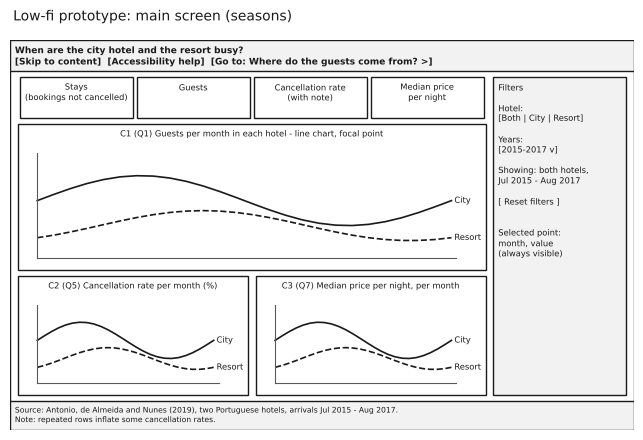

In [4]:
# ── Main screen ───────────────────────────────────────────────────────────────
main_labels = {
    'header': 'When are the city hotel and the resort busy?\n[Skip to content]  [Accessibility help]  [Go to: Where do the guests come from? >]',
    'kpis': ['Stays\n(bookings not cancelled)', 'Guests', 'Cancellation rate\n(with note)', 'Median price\nper night'],
    'filters': FILTERS,
    'footer': 'Source: Antonio, de Almeida and Nunes (2019), two Portuguese hotels, arrivals Jul 2015 - Aug 2017.\nNote: repeated rows inflate some cancellation rates.',
    'chart_main': 'C1 (Q1) Guests per month in each hotel - line chart, focal point',
    'chart_left': 'C2 (Q5) Cancellation rate per month (%)',
    'chart_right': 'C3 (Q7) Median price per night, per month',
}
def main_extra(ax):
    for key in ['chart_main', 'chart_left', 'chart_right']:
        sketch_lines(ax, MAIN[key])

draw_screen(MAIN, 'Low-fi prototype: main screen (seasons)', main_labels, 'lowfi_main_screen.png', main_extra)
plt.show()

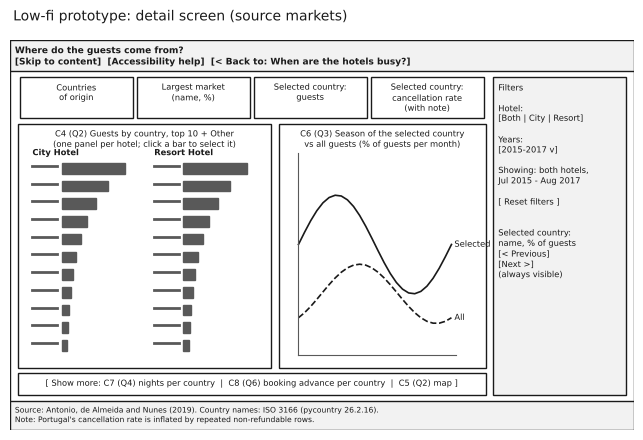

In [5]:
# ── Detail screen ─────────────────────────────────────────────────────────────
detail_labels = {
    'header': 'Where do the guests come from?\n[Skip to content]  [Accessibility help]  [< Back to: When are the hotels busy?]',
    'kpis': ['Countries\nof origin', 'Largest market\n(name, %)', 'Selected country:\nguests', 'Selected country:\ncancellation rate\n(with note)'],
    'filters': FILTERS.replace('Selected point:\nmonth, value', 'Selected country:\nname, % of guests\n[< Previous]\n[Next >]'),
    'footer': 'Source: Antonio, de Almeida and Nunes (2019). Country names: ISO 3166 (pycountry 26.2.16).\nNote: Portugal\'s cancellation rate is inflated by repeated non-refundable rows.',
    'chart_main': 'C4 (Q2) Guests by country, top 10 + Other\n(one panel per hotel; click a bar to select it)',
    'chart_right': 'C6 (Q3) Season of the selected country\nvs all guests (% of guests per month)',
    'show_more': '[ Show more: C7 (Q4) nights per country  |  C8 (Q6) booking advance per country  |  C5 (Q2) map ]',
}
def detail_extra(ax):
    sketch_bars(ax, DETAIL['chart_main'], n=11, panels=2, top=80, panel_titles=['City Hotel', 'Resort Hotel'])
    sketch_lines(ax, DETAIL['chart_right'], series=('Selected', 'All'))

draw_screen(DETAIL, 'Low-fi prototype: detail screen (source markets)', detail_labels, 'lowfi_detail_screen.png', detail_extra)
plt.show()

## 6. Export

In [6]:
# ── Export: the layout grid, so Part 6 can reuse the same sizes ──────────────
rows = [(screen_name, part, *rect) for screen_name, screen in [('frame', FRAME), ('main', MAIN), ('detail', DETAIL)]
        for part, rect in screen.items()]
layout = pd.DataFrame(rows, columns=['screen', 'part', 'x_px', 'y_px', 'width_px', 'height_px'])
layout.to_csv(OUTPUT_DIR / 'layout_grid.csv', index=False)
layout

,screen,part,x_px,y_px,width_px,height_px
0,frame,header,0,0,1280,64
1,frame,kpis,16,76,960,84
2,frame,filters,992,76,272,652
3,frame,footer,0,740,1280,60
4,main,chart_main,16,172,960,300
5,main,chart_left,16,484,472,244
6,main,chart_right,504,484,472,244
7,detail,chart_main,16,172,520,500
8,detail,chart_right,552,172,424,500
9,detail,show_more,16,684,960,44


## Conclusions

1. Both screens share the same frame (header, KPI row, filter panel on the right, footer), so the user learns it once (consistency, course 06).
2. Each screen shows 4 KPIs and at most 3 charts; the main chart is the focal point and takes at least 40 % of the content area.
3. Q4, Q6 and the map are behind "Show more" on the detail screen (progressive disclosure, cognitive accessibility).